In [1]:
import gc                                # garbage collector, used to free RAM
import numpy as np                       # NumPy: numerical arrays
import pandas as pd                      # pandas: tables
import scanpy as sc                      # Scanpy: single-cell analysis
import matplotlib.pyplot as plt          # matplotlib: plotting
from pathlib import Path                 # Path: file and folder paths
from importlib.metadata import version   # used to print package versions without deprecation warnings

project_dir = Path.cwd().parent          # notebook lives in Notebook/, so parent = project root
proc_dir   = project_dir / "data" / "processed"
fig_dir    = project_dir / "Figure"
result_dir = project_dir / "Result"
fig_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

print("scanpy", version("scanpy"), "| igraph", version("igraph"))
adata = sc.read_h5ad(proc_dir / "merged_umap.h5ad")      # log-normalised data + PCA + neighbors + UMAP
print(adata)


scanpy 1.11.5 | igraph 1.0.0
AnnData object with n_obs × n_vars = 13240 × 36601
    obs: 'total_counts', 'timepoint', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'doublet_score', 'scrublet_called', 'high_doublet_score'
    var: 'gene_id', 'mt', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'


In [2]:
resolutions = [0.3, 0.5, 0.8]            # higher resolution -> more, smaller clusters

for r in resolutions:
    key = f"leiden_r{str(r).replace('.', '')}"   # e.g. leiden_r03 (dots in column names are avoided)
    # flavor="igraph", n_iterations=2, directed=False is the setting Scanpy recommends for its igraph backend
    sc.tl.leiden(adata, resolution=r, key_added=key, flavor="igraph", n_iterations=2, directed=False, random_state=0)
    print(key, "->", adata.obs[key].nunique(), "clusters")

cols = [f"leiden_r{str(r).replace('.', '')}" for r in resolutions]
adata.obs[["sample"] + cols].to_csv(result_dir / "leiden_clusters_by_resolution.csv")   # small table, safe for GitHub

leiden_r03 -> 11 clusters
leiden_r05 -> 14 clusters
leiden_r08 -> 19 clusters


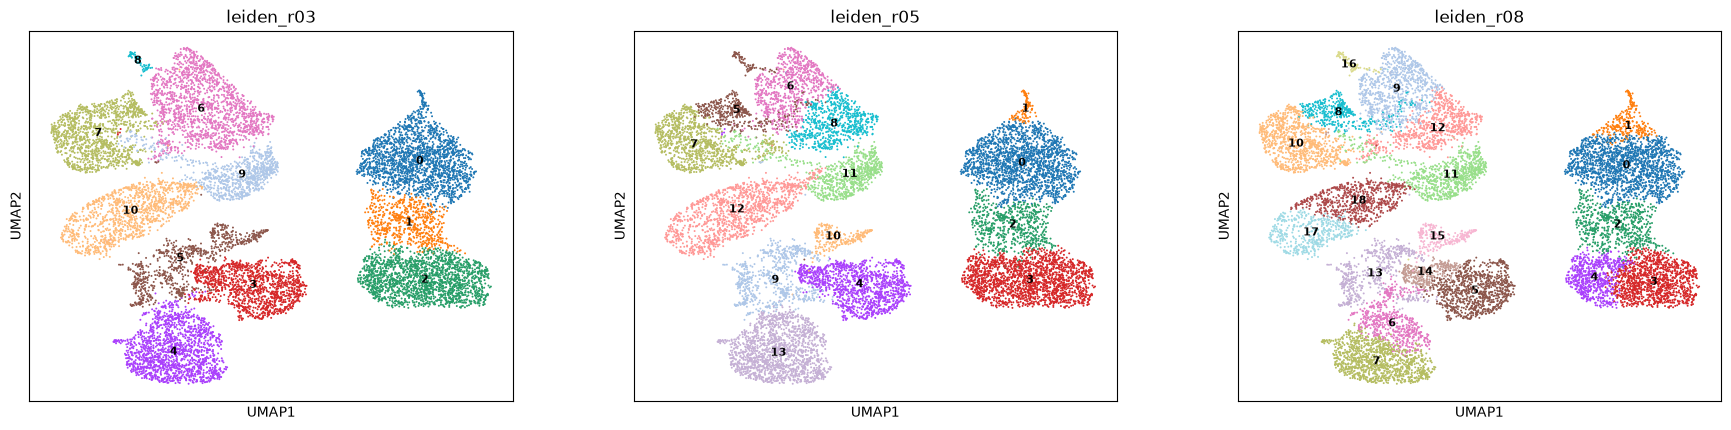

In [3]:
sc.pl.umap(adata, color=cols, ncols=3, size=8, legend_loc="on data", legend_fontsize=8, show=False)
plt.gcf().savefig(fig_dir / "umap_leiden_resolutions.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
key = "leiden_r05"                                                   # reference resolution for this first look
print(pd.crosstab(adata.obs[key], adata.obs["sample"]))              # cells per cluster per sample
print(adata.obs.groupby(key, observed=True)[
    ["doublet_score", "pct_counts_mt", "n_genes_by_counts", "total_counts"]].median().round(2))   # median per cluster

sample        D7  D14   D21
leiden_r05                 
0           1878    0     0
1            102    0     0
2            669    0     0
3           1890    0     0
4              1  353   909
5              0  432    40
6              0  779     1
7              0  894   105
8              0  686     6
9              0   73   594
10             0   15   217
11             0    2   765
12             0    6  1227
13             0    6  1590
            doublet_score  pct_counts_mt  n_genes_by_counts  total_counts
leiden_r05                                                               
0                    0.04           7.56             4750.0       32484.5
1                    0.05           6.19             4507.5       28536.0
2                    0.11           8.27             5493.0       40578.0
3                    0.05           9.04             4683.5       27736.0
4                    0.02           6.80             5704.0       35710.0
5                    0.04         

In [5]:
key = "leiden_r05"                                          # working resolution
d14 = adata.obs[adata.obs["sample"] == "D14"]               # D14 cells only
low_genes = d14["n_genes_by_counts"] < 3500                 # True for the low-gene population seen in the QC histogram
print(pd.crosstab(d14[key], low_genes, rownames=["cluster"], colnames=["n_genes < 3500"]))

n_genes < 3500  False  True 
cluster                     
4                 337     16
5                 334     98
6                 761     18
7                 603    291
8                 673     13
9                  71      2
10                 12      3
11                  0      2
12                  4      2
13                  6      0


In [6]:
# Test only genes detected (non-zero) in at least 10 cells: very rare genes add noise and computation time
n_cells_expr = np.asarray((adata.X > 0).sum(axis=0)).ravel()   # number of cells expressing each gene
adata.var["expressed_10"] = n_cells_expr >= 10                  # boolean column marking the genes to test
print("genes tested:", int(adata.var["expressed_10"].sum()), "of", adata.n_vars)

# Wilcoxon rank-sum test: for each cluster, which genes are higher than in all other cells?
#  mask_var   -> test only the genes flagged above
#  pts=True   -> also store the fraction of cells expressing each gene (in the cluster and outside it)
#  tie_correct-> more accurate p-values when many expression values are tied (common with sparse data)
sc.tl.rank_genes_groups(adata, groupby=key, method="wilcoxon", mask_var="expressed_10", pts=True, tie_correct=True)

genes tested: 26746 of 36601


In [7]:
markers = sc.get.rank_genes_groups_df(adata, group=None)       # all clusters in one table
markers = markers.sort_values(["group", "scores"], ascending=[True, False])   # best markers first within each cluster
markers.to_csv(result_dir / f"markers_{key}.csv", index=False)

# Smaller table for GitHub: top 50 markers per cluster
markers.groupby("group", observed=True).head(50).to_csv(result_dir / f"markers_{key}_top50.csv", index=False)

# Compact printout: top 5 genes per cluster (highest Wilcoxon score)
top5 = markers.groupby("group", observed=True).head(5)
print(top5.groupby("group", observed=True)["names"].apply(lambda x: ", ".join(x)).to_string())

group
0                 LRP2, S100A16, CITED4, S100A14, RFLNA
1                        FMNL1, DHX58, PPY, TFF1, ASGR1
10               LINC00261, LINC02413, IHH, FOXA2, CST4
11                PAGE4, MIR205HG, IFI6, SIGLEC6, MYLPF
12                 DIO2-AS1, EBI3, DIO2, C8orf31, LAIR2
13                      COL6A3, NID2, LUM, ZEB2, COL3A1
2                 DNMT3L, ALPG, TUBB4A, CITED4, SLC12A3
3                         OLAH, SPIC, APELA, GPX2, FGF4
4           FOXD3-AS1, PTPRZ1, SFRP2, AC064802.1, USP44
5     AP005059.1, AL590822.2, KCNA7, CYP19A1, AL3561...
6                 ASCL2, ACVRL1, DIO2-AS1, SLC8A3, DIO2
7                        LHB, LGALS13, CGB2, CGB1, INHA
8                      CCBE1, ITGB4, SYT16, FYB1, MYLPF
9                           VIM, GPC6, NTS, HAS2, CDH11


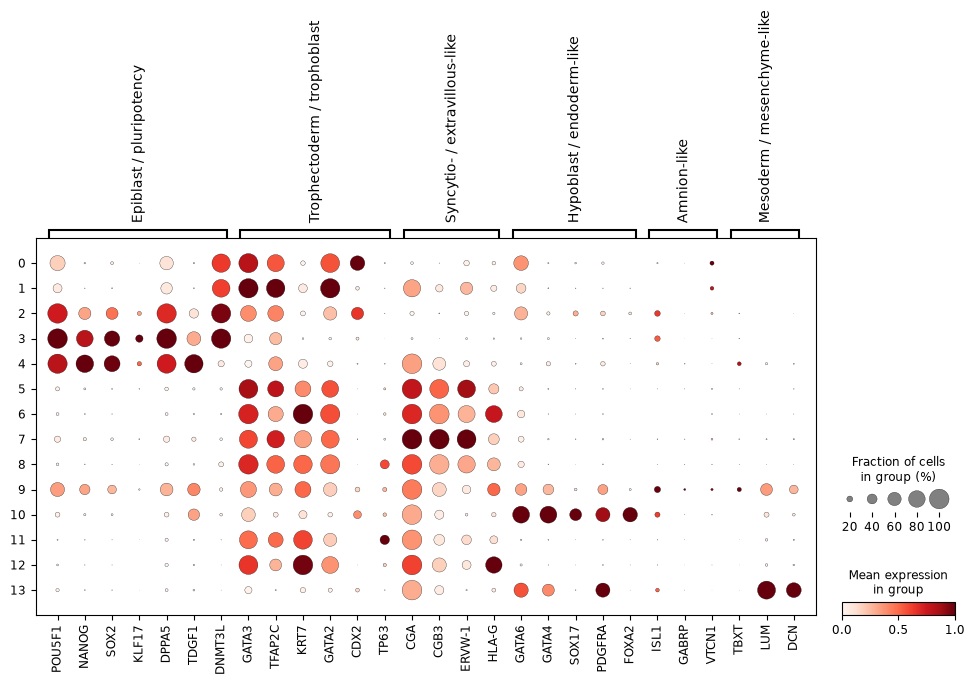

In [8]:
marker_sets = {                                             # starting list: VERIFY against the original paper and literature
    "Epiblast / pluripotency": ["POU5F1", "NANOG", "SOX2", "KLF17", "DPPA5", "TDGF1", "DNMT3L"],
    "Trophectoderm / trophoblast": ["GATA3", "TFAP2C", "KRT7", "GATA2", "CDX2", "TP63"],
    "Syncytio- / extravillous-like": ["CGA", "CGB3", "ERVW-1", "HLA-G"],
    "Hypoblast / endoderm-like": ["GATA6", "GATA4", "SOX17", "PDGFRA", "FOXA2"],
    "Amnion-like": ["ISL1", "GABRP", "VTCN1"],
    "Mesoderm / mesenchyme-like": ["TBXT", "LUM", "DCN"],
}
present = {}                                               # keep only genes that exist in our data
for group, genes in marker_sets.items():
    present[group] = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]
    if missing:
        print("not found in data:", missing)

# Dot size = fraction of cells expressing the gene; colour = mean expression (scaled 0-1 per gene)
sc.pl.dotplot(adata, var_names=present, groupby=key, standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_known_markers_r05.png", dpi=200, bbox_inches="tight")
plt.show()

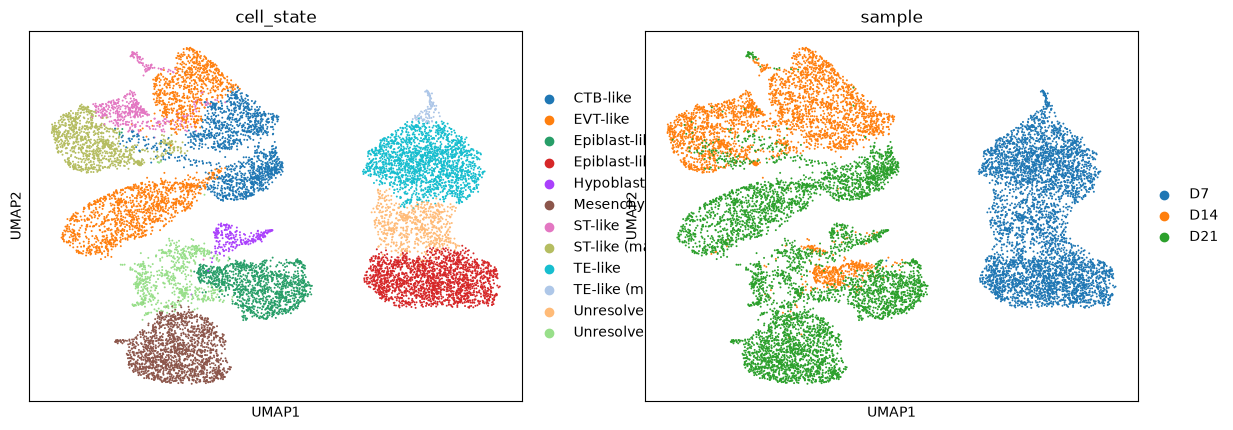

sample                                          D7   D14   D21
cell_state                                                    
CTB-like                                       0.0  21.2  14.1
EVT-like                                       0.0  24.2  22.5
Epiblast-like (later)                          0.0  10.9  16.7
Epiblast-like (naive-like)                    41.6   0.0   0.0
Hypoblast/endoderm-like                        0.0   0.5   4.0
Mesenchyme-like                                0.0   0.2  29.2
ST-like                                        0.0  13.3   0.7
ST-like (mature)                               0.0  27.5   1.9
TE-like                                       41.4   0.0   0.0
TE-like (maturing)                             2.2   0.0   0.0
Unresolved (EPI/TE intermediate or doublets)  14.7   0.0   0.0
Unresolved (mixed/mesenchymal)                 0.0   2.2  10.9


In [9]:
# Tentative labels from marker genes (to be verified against the original paper and literature)
cluster_labels = {
    "0": "TE-like",
    "1": "TE-like (maturing)",
    "2": "Unresolved (EPI/TE intermediate or doublets)",
    "3": "Epiblast-like (naive-like)",
    "4": "Epiblast-like (later)",
    "5": "ST-like",
    "6": "EVT-like",
    "7": "ST-like (mature)",
    "8": "CTB-like",
    "9": "Unresolved (mixed/mesenchymal)",
    "10": "Hypoblast/endoderm-like",
    "11": "CTB-like",
    "12": "EVT-like",
    "13": "Mesenchyme-like",
}
# Map each cell's cluster number to its label; the new column is categorical (a fixed set of labels)
adata.obs["cell_state"] = adata.obs[key].map(cluster_labels).astype("category")

# Two UMAPs: cell state and sample
sc.pl.umap(adata, color=["cell_state", "sample"], ncols=2, size=8, show=False)
plt.gcf().savefig(fig_dir / "umap_cell_states.png", dpi=200, bbox_inches="tight")
plt.show()

# Percentage of each sample made up of each cell state (columns add up to 100)
comp = (pd.crosstab(adata.obs["cell_state"], adata.obs["sample"], normalize="columns") * 100).round(1)
comp.to_csv(result_dir / "cell_state_composition.csv")
print(comp)

In [10]:
genes = ["POU5F1", "DPPA5", "GATA3", "TFAP2C"]                   # EPI markers: POU5F1, DPPA5 ; TE markers: GATA3, TFAP2C
sub = adata[adata.obs["sample"] == "D7", genes].copy()            # D7 cells, 4 genes only
X = sub.layers["counts"]                                          # raw UMI counts (not log-normalised)
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)       # sparse -> dense array (small: 4 genes only)
df = pd.DataFrame(X, columns=sub.var_names, index=sub.obs_names)
df["cluster"] = sub.obs[key].values                               # cluster of each cell
df["EPI_detected"] = (df["POU5F1"] + df["DPPA5"]) > 0             # at least one UMI of an epiblast marker
df["TE_detected"]  = (df["GATA3"] + df["TFAP2C"]) > 0             # at least one UMI of a TE marker
df["both"] = df["EPI_detected"] & df["TE_detected"]               # cells with both signals
print((df.groupby("cluster", observed=True)[["EPI_detected", "TE_detected", "both"]].mean() * 100).round(1))

         EPI_detected  TE_detected  both
cluster                                 
0                84.7         98.0  83.0
1                60.8        100.0  60.8
2               100.0         87.6  87.6
3               100.0         65.1  65.1
4               100.0          0.0   0.0


In [11]:
for g in ["2", "9"]:
    names = markers[markers["group"] == g]["names"].head(20).tolist()   # 20 highest-scoring genes of this cluster
    print(f"cluster {g}: {', '.join(names)}\n")

cluster 2: DNMT3L, ALPG, TUBB4A, CITED4, SLC12A3, KHDC1L, OLAH, YPEL2, SCGB3A2, GPX2, MYBL2, NLRP7, ELF3, NFKB2, ATP6V0D2, RPL29, EEF1G, UQCRH, LARP6, RHOV

cluster 9: VIM, GPC6, NTS, HAS2, CDH11, SOX5, PTPRG, LRFN5, HMGA2, TCF4, AC068587.4, COL1A2, PTPRD, ACTB, BAMBI, GAPDH, SFRP2, AUTS2, IGFBP4, TENM4



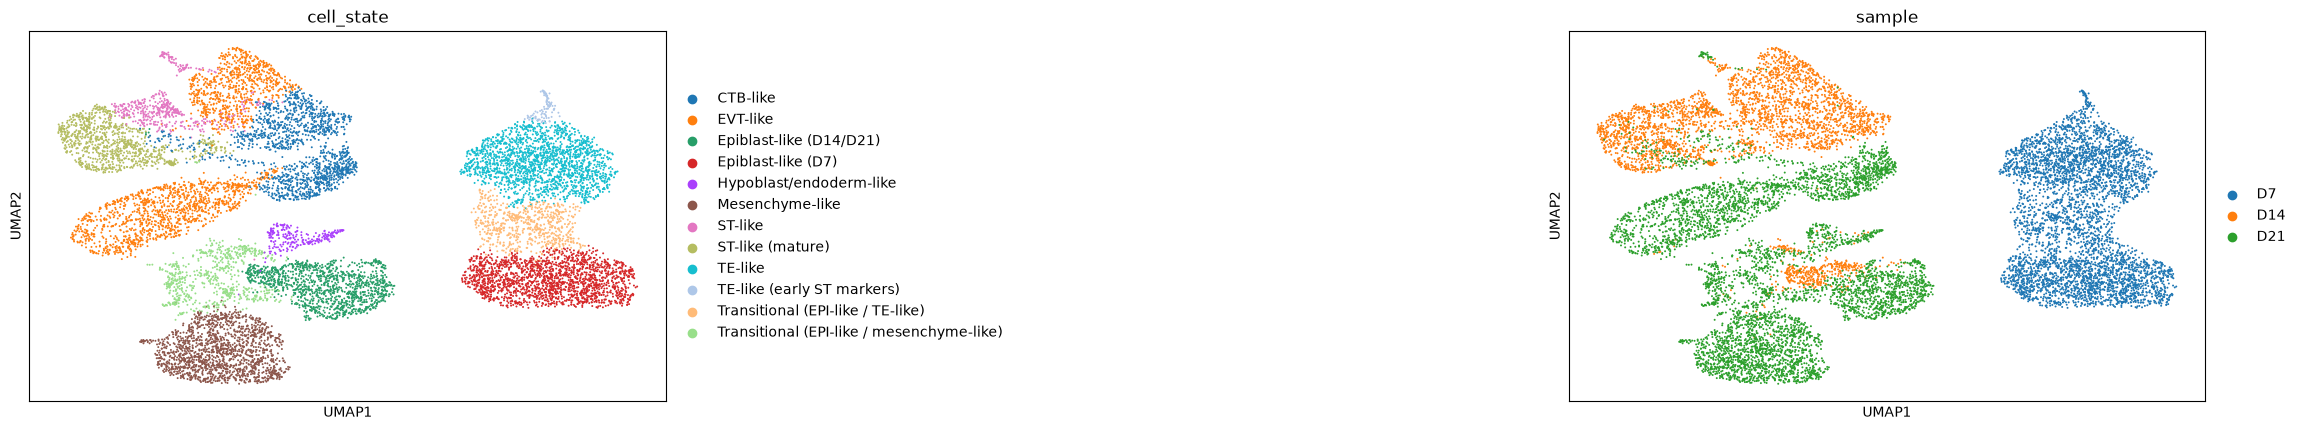

sample                                       D7   D14   D21
cell_state                                                 
CTB-like                                    0.0  21.2  14.1
EVT-like                                    0.0  24.2  22.5
Epiblast-like (D14/D21)                     0.0  10.9  16.7
Epiblast-like (D7)                         41.6   0.0   0.0
Hypoblast/endoderm-like                     0.0   0.5   4.0
Mesenchyme-like                             0.0   0.2  29.2
ST-like                                     0.0  13.3   0.7
ST-like (mature)                            0.0  27.5   1.9
TE-like                                    41.4   0.0   0.0
TE-like (early ST markers)                  2.2   0.0   0.0
Transitional (EPI-like / TE-like)          14.7   0.0   0.0
Transitional (EPI-like / mesenchyme-like)   0.0   2.2  10.9
Saved: 330.333251953125 MB


In [12]:
# Final provisional labels. Clusters 2 and 9 are kept (not removed) and labelled as transitional.
final_labels = {
    "0": "TE-like",
    "1": "TE-like (early ST markers)",
    "2": "Transitional (EPI-like / TE-like)",
    "3": "Epiblast-like (D7)",
    "4": "Epiblast-like (D14/D21)",
    "5": "ST-like",
    "6": "EVT-like",
    "7": "ST-like (mature)",
    "8": "CTB-like",
    "9": "Transitional (EPI-like / mesenchyme-like)",
    "10": "Hypoblast/endoderm-like",
    "11": "CTB-like",
    "12": "EVT-like",
    "13": "Mesenchyme-like",
}
adata.obs["cell_state"] = adata.obs[key].map(final_labels).astype("category")      # one label per cell
adata.obs["flag_transitional_cluster"] = adata.obs[key].isin(["2", "9"])           # flag for the sensitivity analysis later

# wspace widens the gap between the two panels so the long legend is no longer cut off
sc.pl.umap(adata, color=["cell_state", "sample"], ncols=2, wspace=1.2, size=8, show=False)
plt.gcf().savefig(fig_dir / "umap_cell_states.png", dpi=200, bbox_inches="tight")
plt.show()

# Percentage of each sample made up of each cell state (descriptive only: one sample per timepoint)
comp = (pd.crosstab(adata.obs["cell_state"], adata.obs["sample"], normalize="columns") * 100).round(1)
comp.to_csv(result_dir / "cell_state_composition.csv")
print(comp)

adata.write_h5ad(proc_dir / "merged_annotated.h5ad", compression="gzip")           # keep the annotated object for the next notebooks
print("Saved:", (proc_dir / "merged_annotated.h5ad").stat().st_size / 1024**2, "MB")

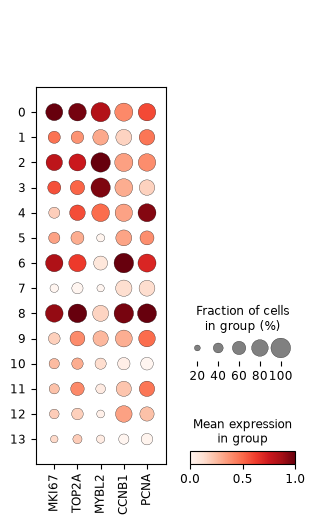

In [13]:
prolif = [g for g in ["MKI67", "TOP2A", "MYBL2", "CCNB1", "PCNA"] if g in adata.var_names]   # proliferation markers present in the data
# Dot size = fraction of cells expressing; colour = mean expression (scaled per gene)
sc.pl.dotplot(adata, var_names=prolif, groupby=key, standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_proliferation_r05.png", dpi=200, bbox_inches="tight")
plt.show()

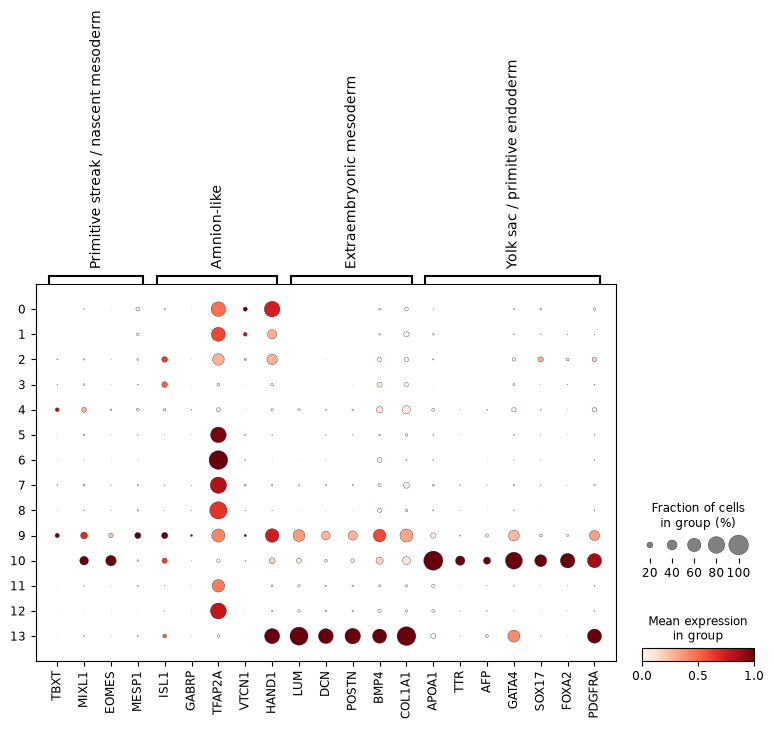

In [14]:
marker_sets2 = {                                                   # starting list: VERIFY against the paper
    "Primitive streak / nascent mesoderm": ["TBXT", "MIXL1", "EOMES", "MESP1"],
    "Amnion-like": ["ISL1", "GABRP", "TFAP2A", "VTCN1", "HAND1"],
    "Extraembryonic mesoderm": ["LUM", "DCN", "POSTN", "BMP4", "COL1A1"],
    "Yolk sac / primitive endoderm": ["APOA1", "TTR", "AFP", "GATA4", "SOX17", "FOXA2", "PDGFRA"],
}
present2 = {}                                                      # keep only genes that exist in our data
for group, genes in marker_sets2.items():
    present2[group] = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]
    if missing:
        print("not found in data:", missing)

sc.pl.dotplot(adata, var_names=present2, groupby=key, standard_scale="var", show=False)   # one row per Leiden cluster
plt.gcf().savefig(fig_dir / "dotplot_gastrulation_markers.png", dpi=200, bbox_inches="tight")
plt.show()

D7 cells per cluster:
 leiden_r05
0    1878
1     102
2     669
3    1890
4       1


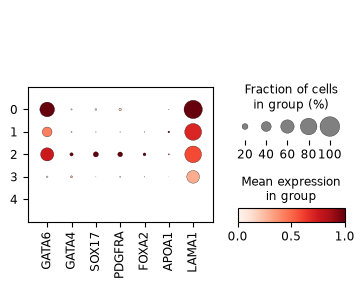

D7 cells with >= 3 PE markers detected: 323 of 4540


In [15]:
d7 = adata[adata.obs["sample"] == "D7"].copy()                     # D7 cells only
pe_genes = [g for g in ["GATA6", "GATA4", "SOX17", "PDGFRA", "FOXA2", "APOA1", "LAMA1"] if g in d7.var_names]
print("D7 cells per cluster:\n", d7.obs[key].value_counts().sort_index().to_string())

sc.pl.dotplot(d7, var_names=pe_genes, groupby=key, standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_D7_PE_markers.png", dpi=200, bbox_inches="tight")
plt.show()

# How many D7 cells have at least 1 UMI for >= 3 of these PE markers?
X = d7[:, pe_genes].layers["counts"]                               # raw counts of the PE markers
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
n_markers_detected = (X > 0).sum(axis=1)                           # per cell: number of PE markers with >= 1 UMI
print("D7 cells with >= 3 PE markers detected:", int((n_markers_detected >= 3).sum()), "of", d7.n_obs)

cluster 2 sub-groups:
leiden_r05_sub
2-9,0    257
2-9,1    208
2-9,2    116
2-9,3     88

cluster 9 sub-groups:
leiden_r05_sub
2-9,4    186
2-9,5    142
2-9,6    126
2-9,7     65
2-9,8    148



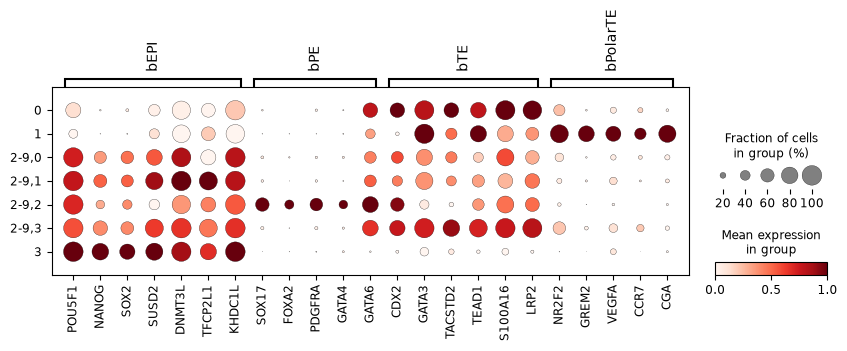

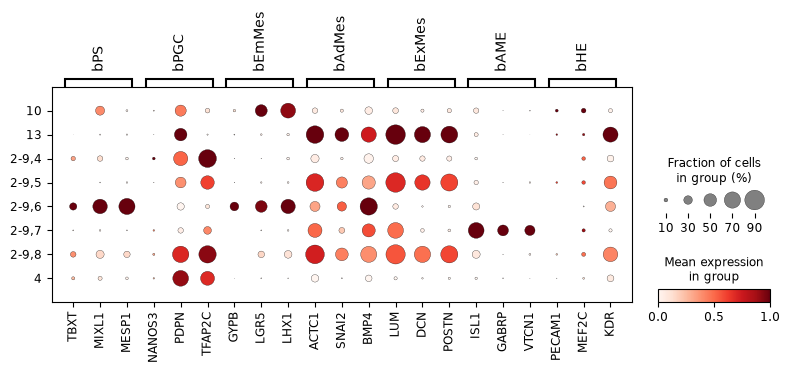

In [16]:
# Subdivide ONLY clusters 2 and 9 into smaller groups; every other cluster keeps its original label
sc.tl.leiden(adata, resolution=0.5, restrict_to=(key, ["2", "9"]), key_added="leiden_r05_sub",
             flavor="igraph", n_iterations=2, directed=False, random_state=0)
for c in ["2", "9"]:
    n = adata.obs.loc[adata.obs[key] == c, "leiden_r05_sub"].value_counts()
    print(f"cluster {c} sub-groups:\n{n[n > 0].sort_index().to_string()}\n")      # sizes of the new sub-groups

# ---- D7: markers of the four D7 populations reported in the paper (bEPI, bPE, bTE, bPolarTE)
d7_sets = {
    "bEPI": ["POU5F1", "NANOG", "SOX2", "SUSD2", "DNMT3L", "TFCP2L1", "KHDC1L"],
    "bPE": ["SOX17", "FOXA2", "PDGFRA", "GATA4", "GATA6"],
    "bTE": ["CDX2", "GATA3", "TACSTD2", "TEAD1", "S100A16", "LRP2"],
    "bPolarTE": ["NR2F2", "GREM2", "VEGFA", "CCR7", "CGA"],
}
d7_sets = {k: [g for g in v if g in adata.var_names] for k, v in d7_sets.items()}   # keep genes present in our data
sub = adata[adata.obs[key].isin(["0", "1", "2", "3"])].copy()                       # D7 clusters only
sub.obs["grp"] = sub.obs["leiden_r05_sub"].astype(str).astype("category")           # sub-group labels as a categorical column
sc.pl.dotplot(sub, var_names=d7_sets, groupby="grp", standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_D7_subclusters_paper_markers.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- D21: markers of the gastrulation-stage populations reported in the paper
d21_sets = {
    "bPS": ["TBXT", "MIXL1", "MESP1"],
    "bPGC": ["NANOS3", "PDPN", "TFAP2C"],
    "bEmMes": ["GYPB", "LGR5", "LHX1"],
    "bAdMes": ["ACTC1", "SNAI2", "BMP4"],
    "bExMes": ["LUM", "DCN", "POSTN"],
    "bAME": ["ISL1", "GABRP", "VTCN1"],
    "bHE": ["PECAM1", "MEF2C", "KDR"],
}
d21_sets = {k: [g for g in v if g in adata.var_names] for k, v in d21_sets.items()}
mask = adata.obs[key].isin(["4", "9", "10", "13"]) & (adata.obs["sample"] == "D21")   # D21 cells of the neighbouring clusters
sub = adata[mask].copy()
sub.obs["grp"] = sub.obs["leiden_r05_sub"].astype(str).astype("category")
sc.pl.dotplot(sub, var_names=d21_sets, groupby="grp", standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_D21_cluster9_subclusters_paper_markers.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
n_genes = adata.obs["n_genes_by_counts"]
too_many = n_genes > 8000        # the authors excluded cells with more than 8,000 detected genes
too_few  = n_genes < 2000        # ...and cells with fewer than 2,000 detected genes
res = pd.DataFrame({
    "cells": adata.obs.groupby(key, observed=True).size(),
    "pct_gt_8000_genes": (too_many.groupby(adata.obs[key], observed=True).mean() * 100).round(1),
    "pct_lt_2000_genes": (too_few.groupby(adata.obs[key], observed=True).mean() * 100).round(1),
})
print(res)

            cells  pct_gt_8000_genes  pct_lt_2000_genes
leiden_r05                                             
0            1878                2.1                1.7
1             102                0.0                1.0
2             669                2.5                1.2
3            1890                0.2                1.2
4            1263               17.6                2.5
5             472                8.1                3.0
6             780                7.8                0.0
7             999               27.7               13.0
8             692               11.3                0.1
9             667               21.7                2.7
10            232               14.2                3.0
11            767                0.8                3.8
12           1233                0.4                2.4
13           1596                2.5                6.3


In [18]:
cols = ["total_counts", "n_genes_by_counts", "doublet_score", "pct_counts_mt"]

def summarise(obs):
    """Median QC values and cell count for each sub-group."""
    g = obs.groupby("leiden_r05_sub", observed=True)
    return g[cols].median().round(2).join(g.size().rename("cells"))

# D7: clusters 0, 1, 3 stay unchanged; cluster 2 is split into sub-groups 2-9,0 ... 2-9,3
d7 = adata.obs[adata.obs[key].isin(["0", "1", "2", "3"])]
print("D7\n", summarise(d7), "\n")

# D21: cells of clusters 4, 10, 13 plus the sub-groups of cluster 9
d21 = adata.obs[adata.obs[key].isin(["4", "9", "10", "13"]) & (adata.obs["sample"] == "D21")]
print("D21\n", summarise(d21))

D7
                 total_counts  n_genes_by_counts  doublet_score  pct_counts_mt  \
leiden_r05_sub                                                                  
0                    32484.5             4750.0           0.04           7.56   
1                    28536.0             4507.5           0.05           6.19   
2-9,0                43155.0             5318.0           0.11           6.77   
2-9,1                39035.5             5694.5           0.10           9.62   
2-9,2                29562.5             4599.0           0.05           8.00   
2-9,3                56735.0             6525.0           0.22           9.15   
3                    27736.0             4683.5           0.05           9.04   

                cells  
leiden_r05_sub         
0                1878  
1                 102  
2-9,0             257  
2-9,1             208  
2-9,2             116  
2-9,3              88  
3                1890   

D21
                 total_counts  n_genes_by_co

0 cells without a label (should be 0)
        sum  size
sample           
D7       88  4540
D14      48  3246
D21     286  5454
sample                                                D7   D14   D21
cell_state_v2                                                       
Amnion-like (bAME)                                   0.0   0.1   1.1
CTB-like (bCTB)                                      0.0  21.2  14.1
EVT-like (bEVT)                                      0.0  24.2  22.5
Endoderm-like (bDE/bYSE)                             0.0   0.5   4.0
Epiblast-like (TE-primed, D7)                       10.2   0.0   0.0
Epiblast-like (bEPI, D14/D21)                        0.0  10.9  16.7
Epiblast-like (bEPI, D7)                            41.6   0.0   0.0
Mesoderm-like (bAdMes/bExMes)                        0.0   0.2  29.2
Mesoderm-like (intermediate)                         0.0   0.1   2.5
Polar TE-like (bPolarTE)                             2.2   0.0   0.0
Primitive endoderm-like (bPE)               

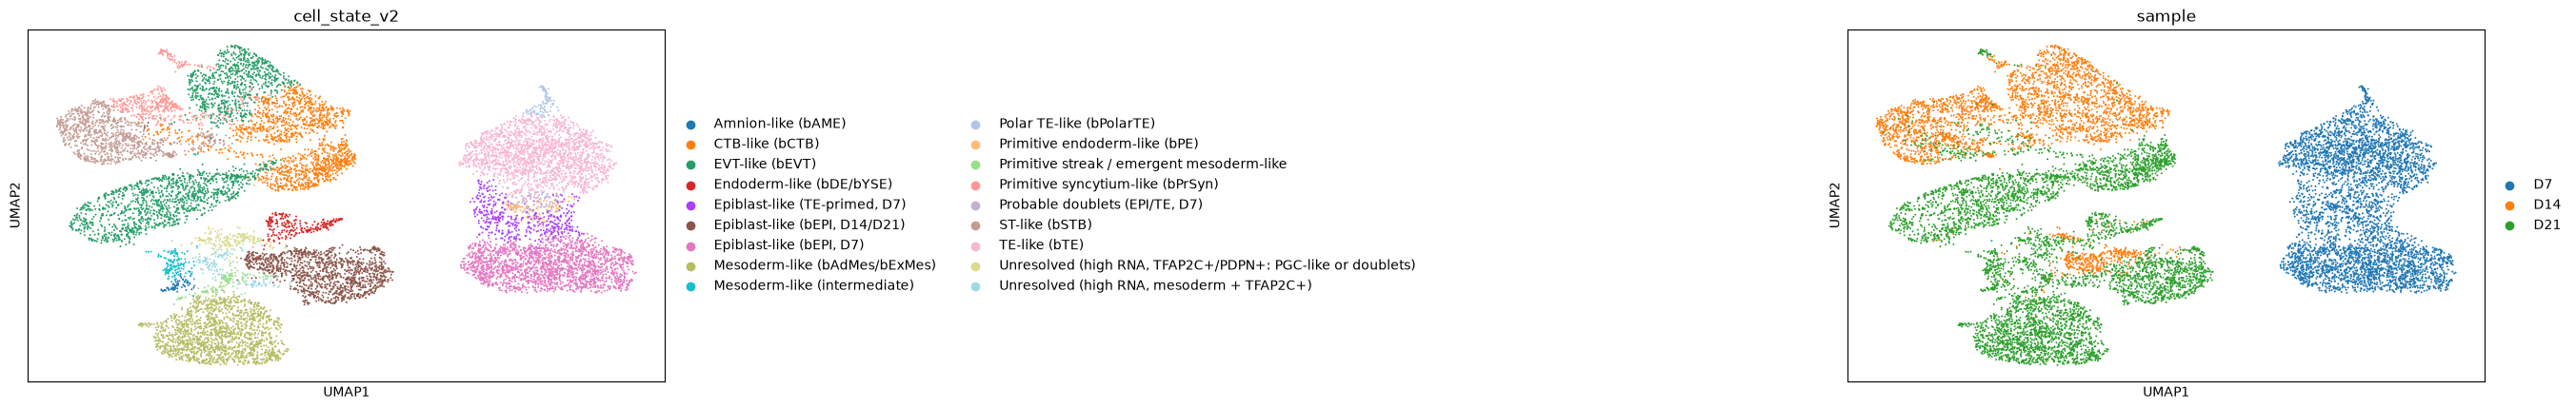

Saved: 330.37085723876953 MB


In [19]:
# Labels for clusters that were NOT split (names follow the original study; "-like" because we infer them from markers)
label_by_cluster = {
    "0": "TE-like (bTE)",
    "1": "Polar TE-like (bPolarTE)",
    "3": "Epiblast-like (bEPI, D7)",
    "4": "Epiblast-like (bEPI, D14/D21)",
    "5": "Primitive syncytium-like (bPrSyn)",
    "6": "EVT-like (bEVT)",
    "7": "ST-like (bSTB)",
    "8": "CTB-like (bCTB)",
    "10": "Endoderm-like (bDE/bYSE)",
    "11": "CTB-like (bCTB)",
    "12": "EVT-like (bEVT)",
    "13": "Mesoderm-like (bAdMes/bExMes)",
}
# Labels for the sub-groups of clusters 2 and 9, based on markers AND on UMI / doublet-score checks (Cell 18)
label_by_sub = {
    "2-9,0": "Epiblast-like (TE-primed, D7)",
    "2-9,1": "Epiblast-like (TE-primed, D7)",
    "2-9,2": "Primitive endoderm-like (bPE)",
    "2-9,3": "Probable doublets (EPI/TE, D7)",
    "2-9,4": "Unresolved (high RNA, TFAP2C+/PDPN+: PGC-like or doublets)",
    "2-9,5": "Mesoderm-like (intermediate)",
    "2-9,6": "Primitive streak / emergent mesoderm-like",
    "2-9,7": "Amnion-like (bAME)",
    "2-9,8": "Unresolved (high RNA, mesoderm + TFAP2C+)",
}

sub = adata.obs["leiden_r05_sub"].astype(str)                    # sub-group label of every cell (equals the cluster for unsplit clusters)
is_split = adata.obs[key].isin(["2", "9"])                       # cells that belong to the two split clusters
v2 = adata.obs[key].astype(str).map(label_by_cluster)            # first label every cell by its cluster
v2.loc[is_split] = sub[is_split].map(label_by_sub)               # then overwrite the split clusters by sub-group
adata.obs["cell_state_v2"] = v2.astype("category")
print(int(adata.obs["cell_state_v2"].isna().sum()), "cells without a label (should be 0)")

# Flags only: NO cell is removed from the object
adata.obs["flag_probable_doublet"]    = sub.eq("2-9,3")
adata.obs["flag_unresolved_high_rna"] = sub.isin(["2-9,4", "2-9,8"])
adata.obs["exclude_default"] = adata.obs["flag_probable_doublet"] | adata.obs["flag_unresolved_high_rna"]
print(adata.obs.groupby("sample", observed=True)["exclude_default"].agg(["sum", "size"]))   # flagged cells per sample

comp = (pd.crosstab(adata.obs["cell_state_v2"], adata.obs["sample"], normalize="columns") * 100).round(1)
comp.to_csv(result_dir / "cell_state_v2_composition.csv")        # small table, safe for GitHub
print(comp)

sc.pl.umap(adata, color=["cell_state_v2", "sample"], ncols=2, wspace=1.6, size=8, show=False)
plt.gcf().savefig(fig_dir / "umap_cell_states_v2.png", dpi=200, bbox_inches="tight")
plt.show()

adata.write_h5ad(proc_dir / "merged_annotated_v2.h5ad", compression="gzip")
print("Saved:", (proc_dir / "merged_annotated_v2.h5ad").stat().st_size / 1024**2, "MB")

In [2]:
qc = pd.read_csv(result_dir / "qc_metrics_before_filtering.csv", index_col=0)   # per-cell QC table (index = barcode)
qc.index = qc.index + "_" + qc["timepoint"]                                      # make the index <barcode>_<sample>, as in the labels table
lab = pd.read_csv(result_dir / "cell_state_v3_labels.csv", index_col=0)         # cluster labels per cell
df = lab.join(qc[["pct_counts_ribo", "pct_counts_mt"]])                          # attach the QC columns to every cell
print(df.groupby("leiden_r05")[["pct_counts_ribo", "pct_counts_mt"]].median().round(1))

            pct_counts_ribo  pct_counts_mt
leiden_r05                                
0                      34.0            7.6
1                      32.9            6.2
2                      34.3            8.3
3                      33.3            9.0
4                      31.6            6.8
5                      16.9            7.2
6                      25.9            7.1
7                      21.0            4.3
8                      27.5            8.2
9                      29.2            6.4
10                     27.6            3.0
11                     36.4           10.2
12                     31.5            8.6
13                     31.5            6.1
